<a href="https://colab.research.google.com/github/gabriduarte2000-glitch/Trabalho-6---Transformadas-de-Wavelet---Gabriel-e-Felipe/blob/main/Trabalho_6_Transformadas_de_Wavelet_Gabriel_e_Felipe.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
!pip -q install PyWavelets
!git clone -q https://github.com/rafaelschaves/gele7317-proc-sin 2>/dev/null || echo "repo já clonado"

repo já clonado


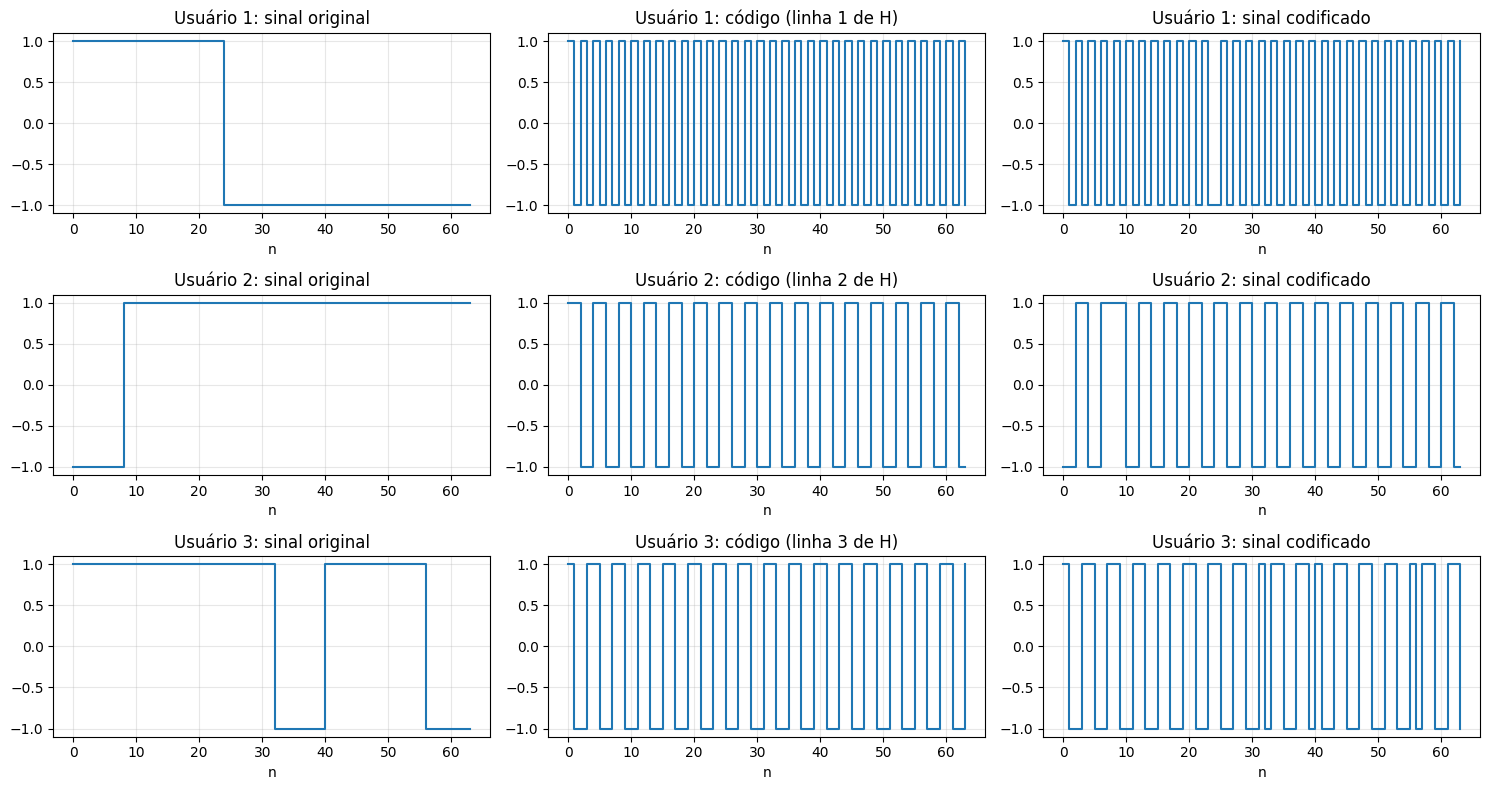

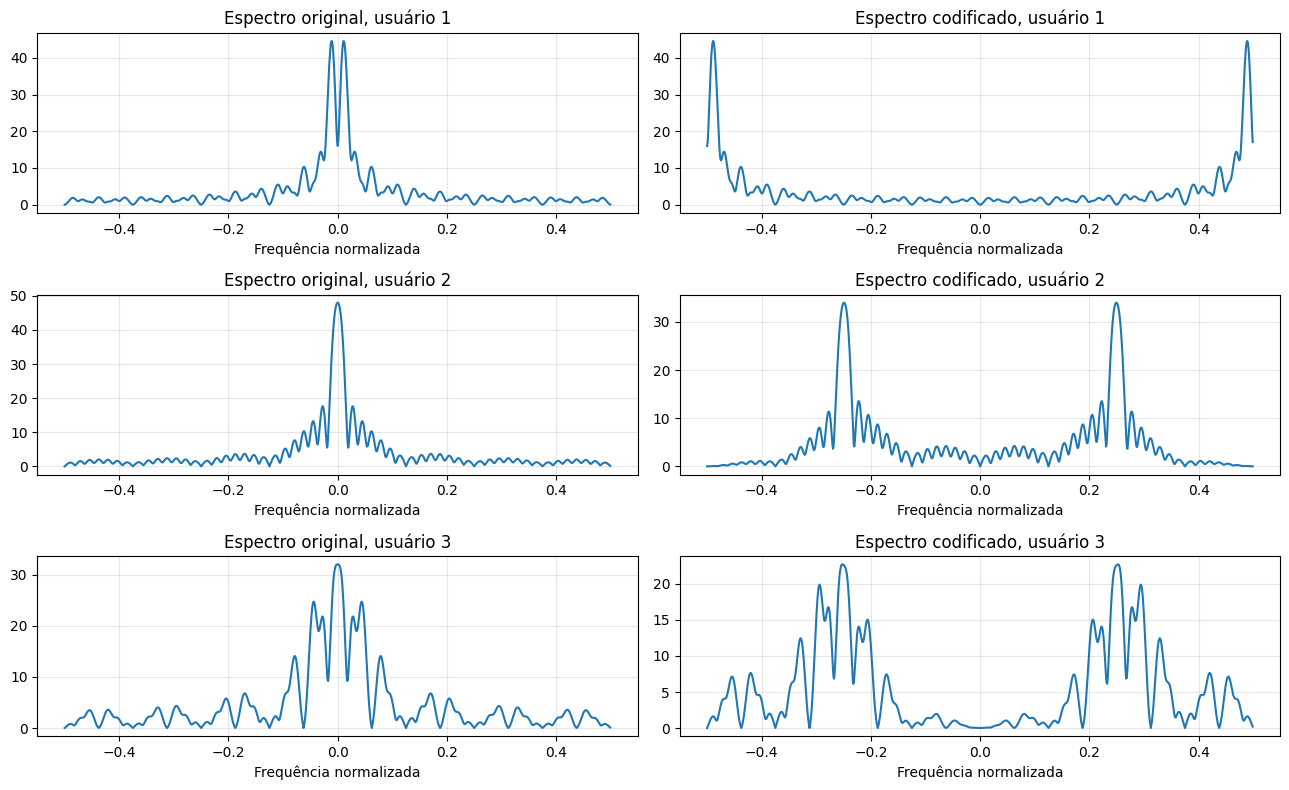

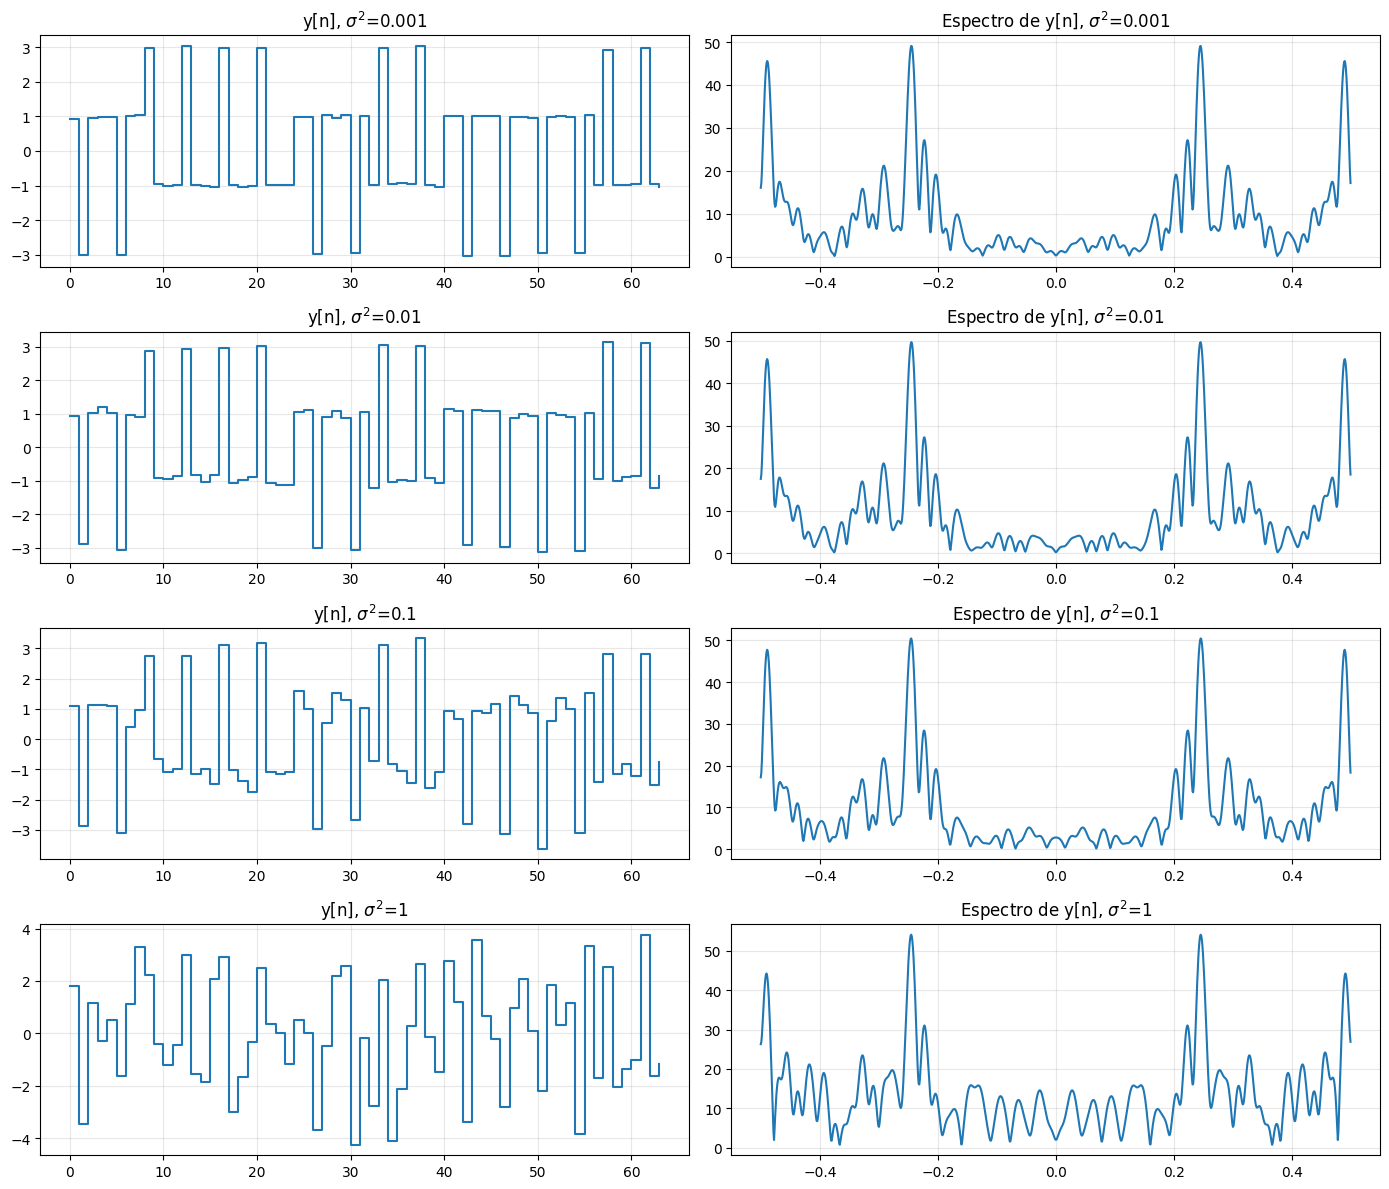


(c) y_j = C^T m_j + w_j, com C C^T = C^T C = 8 I
    m_hat_j = (1/8) C y_j = m_j + (1/8) C w_j
    m_hat_k[j] = m_k[j] + (1/8) c_k^T w_j
    Ruído efetivo: N(0, sigma^2/8)
    Decisão: sign(m_hat_k), Pe = Q(sqrt(8/sigma^2))

Usuário 1  m   : [-1  1 -1  1 -1  1 -1  1]
           m_hat: [-0.95  0.98 -0.96  1.1  -1.1   0.96 -1.07  0.82]  decisão: [-1  1 -1  1 -1  1 -1  1]
Usuário 2  m   : [-1 -1 -1  1  1  1 -1  1]
           m_hat: [-0.96 -1.01 -1.06  1.06  0.88  0.98 -1.18  1.16]  decisão: [-1 -1 -1  1  1  1 -1  1]
Usuário 3  m   : [ 1  1  1  1 -1 -1 -1  1]
           m_hat: [ 1.11  0.89  1.2   0.97 -1.32 -1.02 -1.05  1.13]  decisão: [ 1  1  1  1 -1 -1 -1  1]


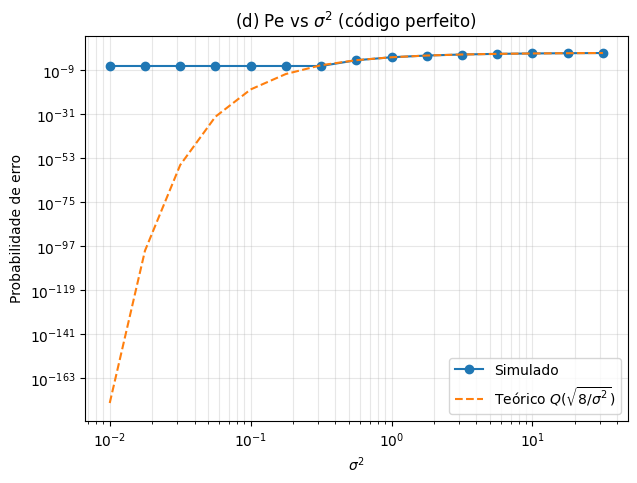


(e) C_hat = C + W, w[n] = 0
    m_hat_j = (1/8)(C + W) C^T m_j = m_j + (1/8) W x_j, com x_j = C^T m_j
    ||x_j||^2 = 8K
    Erro efetivo em m_hat_k: N(0, K sigma^2 / 8), K = 3
    Pe = Q(sqrt(8/(K sigma^2)))

Usuário 1  m   : [-1  1 -1  1 -1  1 -1  1]
           m_hat: [-1.24  1.04 -1.24  1.24 -1.04  1.24 -1.24  1.24]  decisão: [-1  1 -1  1 -1  1 -1  1]
Usuário 2  m   : [-1 -1 -1  1  1  1 -1  1]
           m_hat: [-0.99 -0.74 -0.99  1.21  0.74  0.99 -1.21  1.21]  decisão: [-1 -1 -1  1  1  1 -1  1]
Usuário 3  m   : [ 1  1  1  1 -1 -1 -1  1]
           m_hat: [ 0.79  0.91  0.79  1.12 -0.91 -0.79 -1.12  1.12]  decisão: [ 1  1  1  1 -1 -1 -1  1]


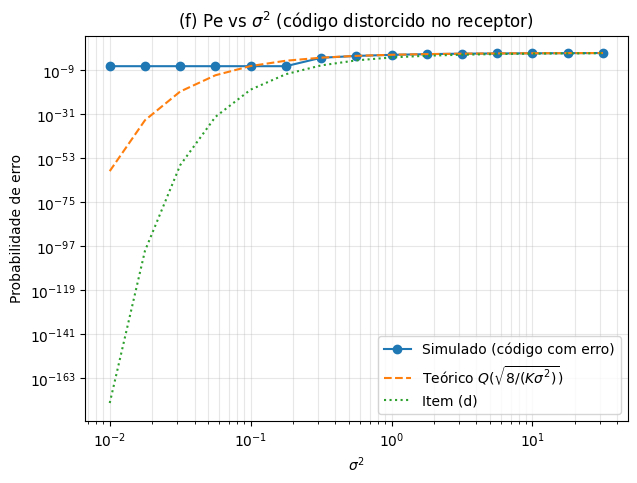

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.linalg import hadamard
from scipy.stats import norm

rng = np.random.default_rng(0)

L = 8
users = [1, 2, 3]
K = len(users)
C = hadamard(L).astype(float)
Nsym = 8

def gera_simbolos(N):
    M = np.zeros((L, N))
    for u in users:
        M[u] = rng.choice([-1, 1], size=N)
    return M

def espectro(sig, nfft=1024):
    S = np.fft.fftshift(np.fft.fft(sig, nfft))
    f = np.fft.fftshift(np.fft.fftfreq(nfft))
    return f, np.abs(S)

M = gera_simbolos(Nsym)
X = {u: np.outer(C[u], M[u]).flatten(order='F') for u in users}

fig, ax = plt.subplots(3, 3, figsize=(15, 8))
for i, u in enumerate(users):
    orig = np.repeat(M[u], L)
    cod = np.tile(C[u], Nsym)
    ax[i, 0].step(range(len(orig)), orig, where='post'); ax[i, 0].set_title(f'Usuário {i+1}: sinal original')
    ax[i, 1].step(range(len(cod)), cod, where='post'); ax[i, 1].set_title(f'Usuário {i+1}: código (linha {u} de H)')
    ax[i, 2].step(range(len(X[u])), X[u], where='post'); ax[i, 2].set_title(f'Usuário {i+1}: sinal codificado')
    for a in ax[i]:
        a.set_xlabel('n'); a.grid(alpha=.3)
plt.tight_layout(); plt.show()

fig, ax = plt.subplots(3, 2, figsize=(13, 8))
for i, u in enumerate(users):
    f, S0 = espectro(np.repeat(M[u], L))
    f, S1 = espectro(X[u])
    ax[i, 0].plot(f, S0); ax[i, 0].set_title(f'Espectro original, usuário {i+1}')
    ax[i, 1].plot(f, S1); ax[i, 1].set_title(f'Espectro codificado, usuário {i+1}')
    for a in ax[i]:
        a.set_xlabel('Frequência normalizada'); a.grid(alpha=.3)
plt.tight_layout(); plt.show()

x_total = sum(X[u] for u in users)
sig2_list = [1e-3, 1e-2, 1e-1, 1]
fig, ax = plt.subplots(4, 2, figsize=(14, 12))
for i, s2 in enumerate(sig2_list):
    w = rng.normal(0, np.sqrt(s2), len(x_total))
    y = x_total + w
    ax[i, 0].step(range(len(y)), y, where='post'); ax[i, 0].set_title(f'y[n], $\\sigma^2$={s2}')
    f, S = espectro(y)
    ax[i, 1].plot(f, S); ax[i, 1].set_title(f'Espectro de y[n], $\\sigma^2$={s2}')
    for a in ax[i]:
        a.grid(alpha=.3)
plt.tight_layout(); plt.show()

print("""
(c) y_j = C^T m_j + w_j, com C C^T = C^T C = 8 I
    m_hat_j = (1/8) C y_j = m_j + (1/8) C w_j
    m_hat_k[j] = m_k[j] + (1/8) c_k^T w_j
    Ruído efetivo: N(0, sigma^2/8)
    Decisão: sign(m_hat_k), Pe = Q(sqrt(8/sigma^2))
""")

def pe_simulado(s2, N=200000):
    M = gera_simbolos(N)
    Y = C.T @ M + rng.normal(0, np.sqrt(s2), (L, N))
    Mh = (C @ Y) / L
    return np.mean(np.sign(Mh[users]) != M[users])

M_ex = gera_simbolos(Nsym)
Y_ex = C.T @ M_ex + rng.normal(0, np.sqrt(0.1), (L, Nsym))
Mh_ex = (C @ Y_ex) / L
for i, u in enumerate(users):
    print(f"Usuário {i+1}  m   :", M_ex[u].astype(int))
    print("           m_hat:", np.round(Mh_ex[u], 2), " decisão:", np.sign(Mh_ex[u]).astype(int))

s2_vec = np.logspace(-2, 1.5, 15)
pe_sim = [pe_simulado(s) for s in s2_vec]
pe_teo = norm.sf(np.sqrt(L / s2_vec))
plt.figure(figsize=(7, 5))
plt.semilogy(s2_vec, np.maximum(pe_sim, 1e-7), 'o-', label='Simulado')
plt.semilogy(s2_vec, pe_teo, '--', label='Teórico $Q(\\sqrt{8/\\sigma^2})$')
plt.xscale('log'); plt.xlabel('$\\sigma^2$'); plt.ylabel('Probabilidade de erro')
plt.grid(alpha=.3, which='both'); plt.legend()
plt.title('(d) Pe vs $\\sigma^2$ (código perfeito)'); plt.show()

print(f"""
(e) C_hat = C + W, w[n] = 0
    m_hat_j = (1/8)(C + W) C^T m_j = m_j + (1/8) W x_j, com x_j = C^T m_j
    ||x_j||^2 = 8K
    Erro efetivo em m_hat_k: N(0, K sigma^2 / 8), K = {K}
    Pe = Q(sqrt(8/(K sigma^2)))
""")

def pe_codigo_errado(s2, nblk=200, Nblk=2000):
    err = 0; tot = 0
    for _ in range(nblk):
        Wm = rng.normal(0, np.sqrt(s2), (L, L))
        Chat = C + Wm
        M = gera_simbolos(Nblk)
        Y = C.T @ M
        Mh = (Chat @ Y) / L
        err += np.sum(np.sign(Mh[users]) != M[users]); tot += K * Nblk
    return err / tot

Wm = rng.normal(0, np.sqrt(0.1), (L, L))
Mh_ex = ((C + Wm) @ (C.T @ M_ex)) / L
for i, u in enumerate(users):
    print(f"Usuário {i+1}  m   :", M_ex[u].astype(int))
    print("           m_hat:", np.round(Mh_ex[u], 2), " decisão:", np.sign(Mh_ex[u]).astype(int))

pe_f = [pe_codigo_errado(s) for s in s2_vec]
pe_f_teo = norm.sf(np.sqrt(L / (K * s2_vec)))
plt.figure(figsize=(7, 5))
plt.semilogy(s2_vec, np.maximum(pe_f, 1e-7), 'o-', label='Simulado (código com erro)')
plt.semilogy(s2_vec, pe_f_teo, '--', label='Teórico $Q(\\sqrt{8/(K\\sigma^2)})$')
plt.semilogy(s2_vec, pe_teo, ':', label='Item (d)')
plt.xscale('log'); plt.xlabel('$\\sigma^2$'); plt.ylabel('Probabilidade de erro')
plt.grid(alpha=.3, which='both'); plt.legend()
plt.title('(f) Pe vs $\\sigma^2$ (código distorcido no receptor)'); plt.show()

Vetores 1D encontrados: {'t': 2001, 'x': 2001, 'pos_sin': 6, 'T_sin': 5, 't_segment_values': 3, 'amp_imp': 5, 'pos_imp': 5, 'T_imp': 5}
Sinal usado: t | amostras: 2001


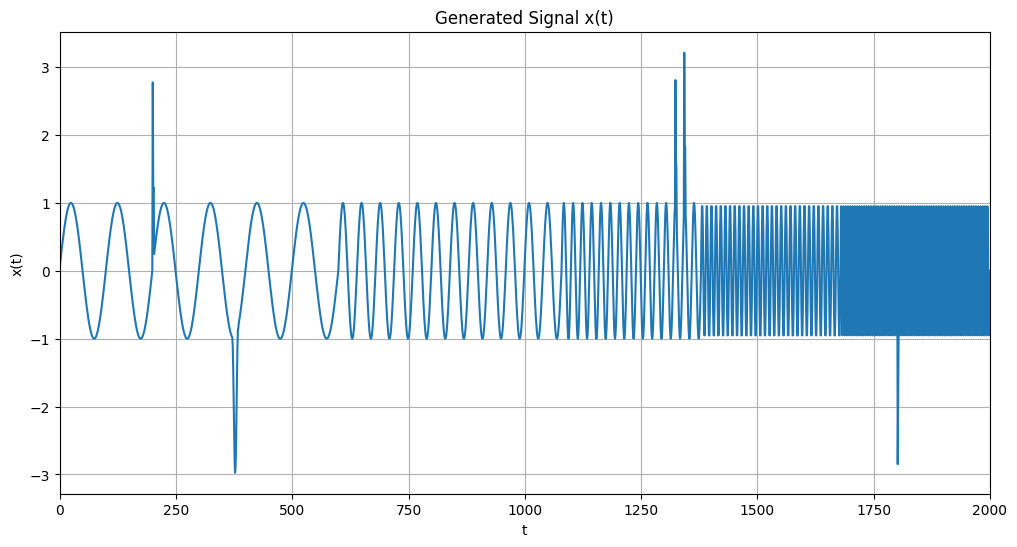

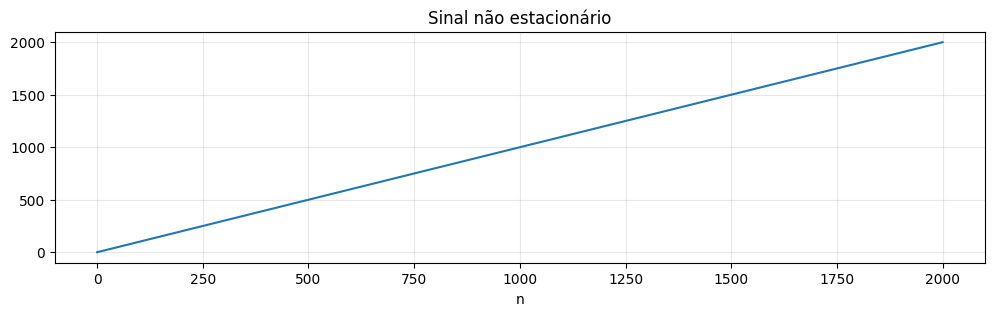

In [ ]:
import glob, json
import numpy as np
import matplotlib.pyplot as plt
import pywt

nb_path = glob.glob('/content/gele7317-proc-sin/**/non_stationary_signal.ipynb', recursive=True)[0]
nb = json.load(open(nb_path))
ns = {}
_show = plt.show
plt.show = lambda *a, **k: None
for cell in nb['cells']:
    if cell['cell_type'] == 'code':
        src = ''.join(cell['source'])
        src = '\n'.join(l for l in src.split('\n') if not l.strip().startswith(('%', '!')))
        try:
            exec(src, ns)
        except Exception as e:
            print("Aviso ao executar célula:", e)
plt.show = _show

cands = {k: v for k, v in ns.items() if isinstance(v, np.ndarray) and v.ndim == 1 and np.issubdtype(v.dtype, np.number) and not k.startswith('_')}
print("Vetores 1D encontrados:", {k: len(v) for k, v in cands.items()})
nome_sinal = max(cands, key=lambda k: len(cands[k]))
x = cands[nome_sinal].astype(float)
print("Sinal usado:", nome_sinal, "| amostras:", len(x))
plt.figure(figsize=(12, 3)); plt.plot(x); plt.title('Sinal não estacionário'); plt.xlabel('n'); plt.grid(alpha=.3); plt.show()

Análise passa-baixas (h0) [ 0.        0.037828 -0.023849 -0.110624  0.377403  0.852699  0.377403
 -0.110624 -0.023849  0.037828]
Análise passa-altas (h1) [-0.       -0.064539  0.040689  0.418092 -0.788486  0.418092  0.040689
 -0.064539 -0.        0.      ]
Síntese passa-baixas (g0) [ 0.       -0.064539 -0.040689  0.418092  0.788486  0.418092 -0.040689
 -0.064539  0.        0.      ]
Síntese passa-altas (g1) [ 0.       -0.037828 -0.023849  0.110624  0.377403 -0.852699  0.377403
  0.110624 -0.023849 -0.037828]


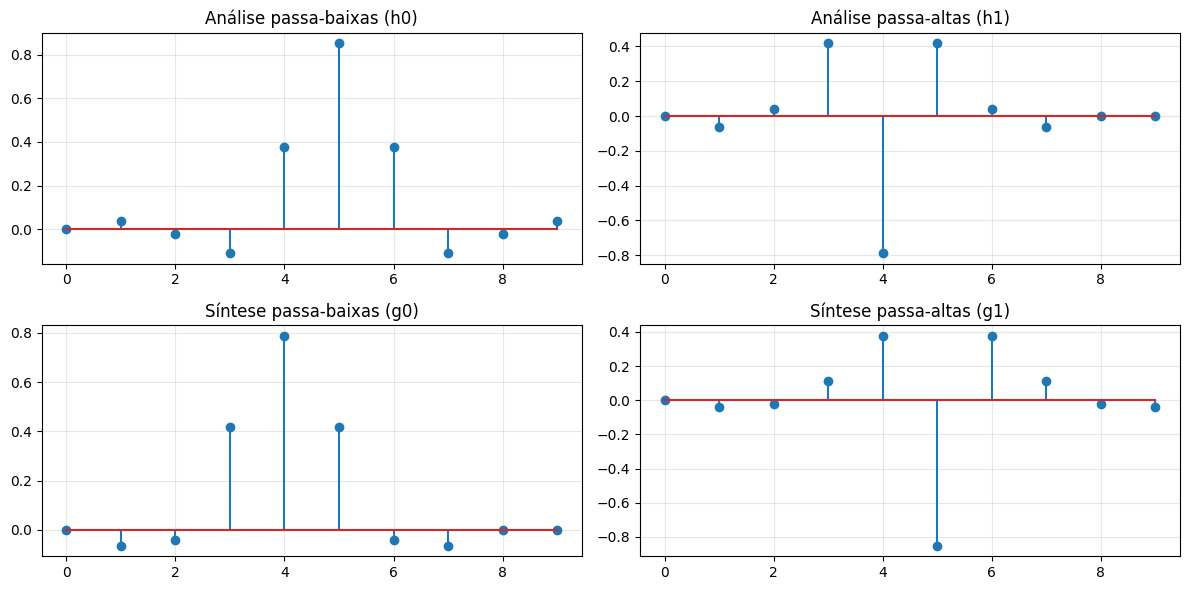

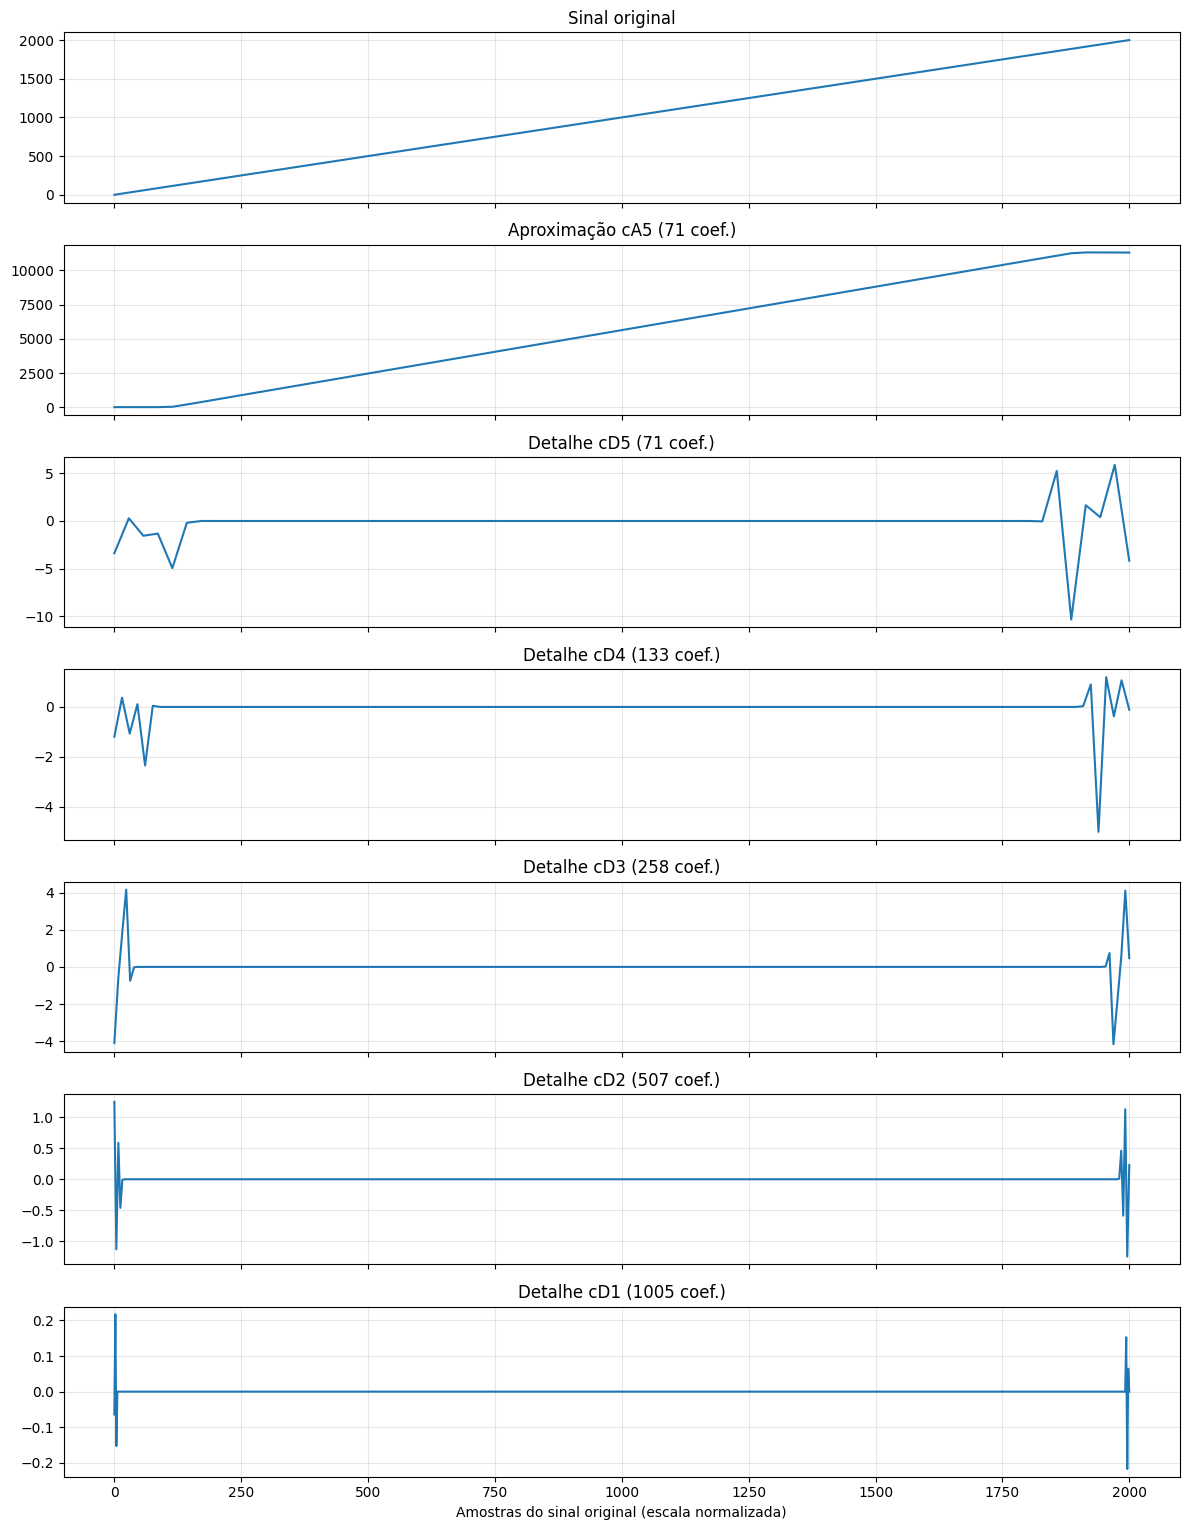

Erro máximo de reconstrução: 3.921641830717526e-11


In [ ]:
w = pywt.Wavelet('bior4.4')
bancos = {'Análise passa-baixas (h0)': w.dec_lo, 'Análise passa-altas (h1)': w.dec_hi,
          'Síntese passa-baixas (g0)': w.rec_lo, 'Síntese passa-altas (g1)': w.rec_hi}
fig, ax = plt.subplots(2, 2, figsize=(12, 6))
for a, (nome, h) in zip(ax.ravel(), bancos.items()):
    a.stem(h); a.set_title(nome); a.grid(alpha=.3)
    print(nome, np.round(h, 6))
plt.tight_layout(); plt.show()

nivel = 5
coefs = pywt.wavedec(x, 'bior4.4', level=nivel)
nomes = [f'Aproximação cA{nivel}'] + [f'Detalhe cD{j}' for j in range(nivel, 0, -1)]

fig, ax = plt.subplots(nivel + 2, 1, figsize=(12, 2.2 * (nivel + 2)), sharex=True)
ax[0].plot(np.arange(len(x)), x); ax[0].set_title('Sinal original'); ax[0].grid(alpha=.3)
for a, c, nome in zip(ax[1:], coefs, nomes):
    t = np.linspace(0, len(x) - 1, len(c))
    a.plot(t, c); a.set_title(f'{nome} ({len(c)} coef.)'); a.grid(alpha=.3)
ax[-1].set_xlabel('Amostras do sinal original (escala normalizada)')
plt.tight_layout(); plt.show()

xr = pywt.waverec(coefs, 'bior4.4')[:len(x)]
print("Erro máximo de reconstrução:", np.max(np.abs(x - xr)))

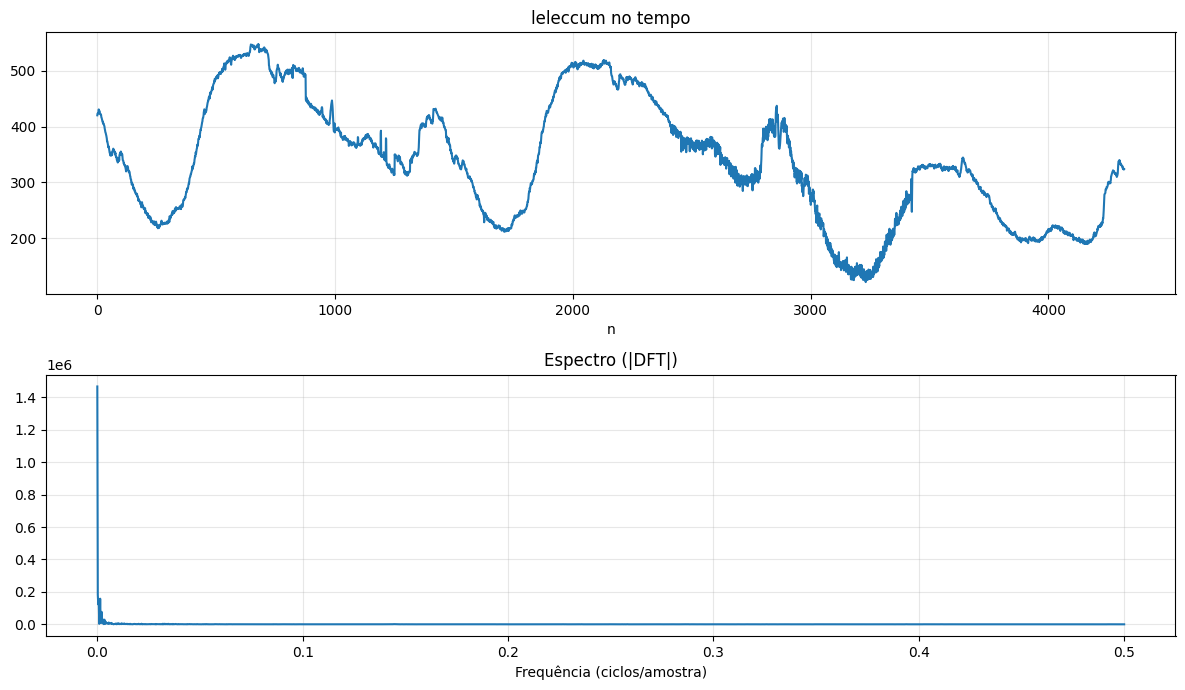

Análise passa-baixas [-0.010597  0.032883  0.030841 -0.187035 -0.027984  0.630881  0.714847
  0.230378]
Análise passa-altas [-0.230378  0.714847 -0.630881 -0.027984  0.187035  0.030841 -0.032883
 -0.010597]
Síntese passa-baixas [ 0.230378  0.714847  0.630881 -0.027984 -0.187035  0.030841  0.032883
 -0.010597]
Síntese passa-altas [-0.010597 -0.032883  0.030841  0.187035 -0.027984 -0.630881  0.714847
 -0.230378]


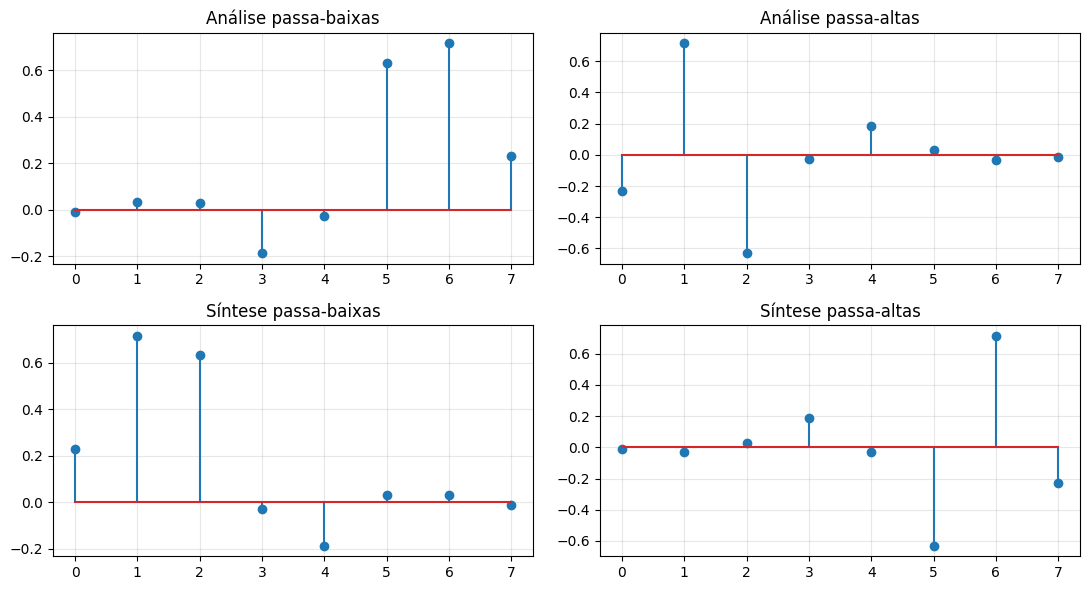

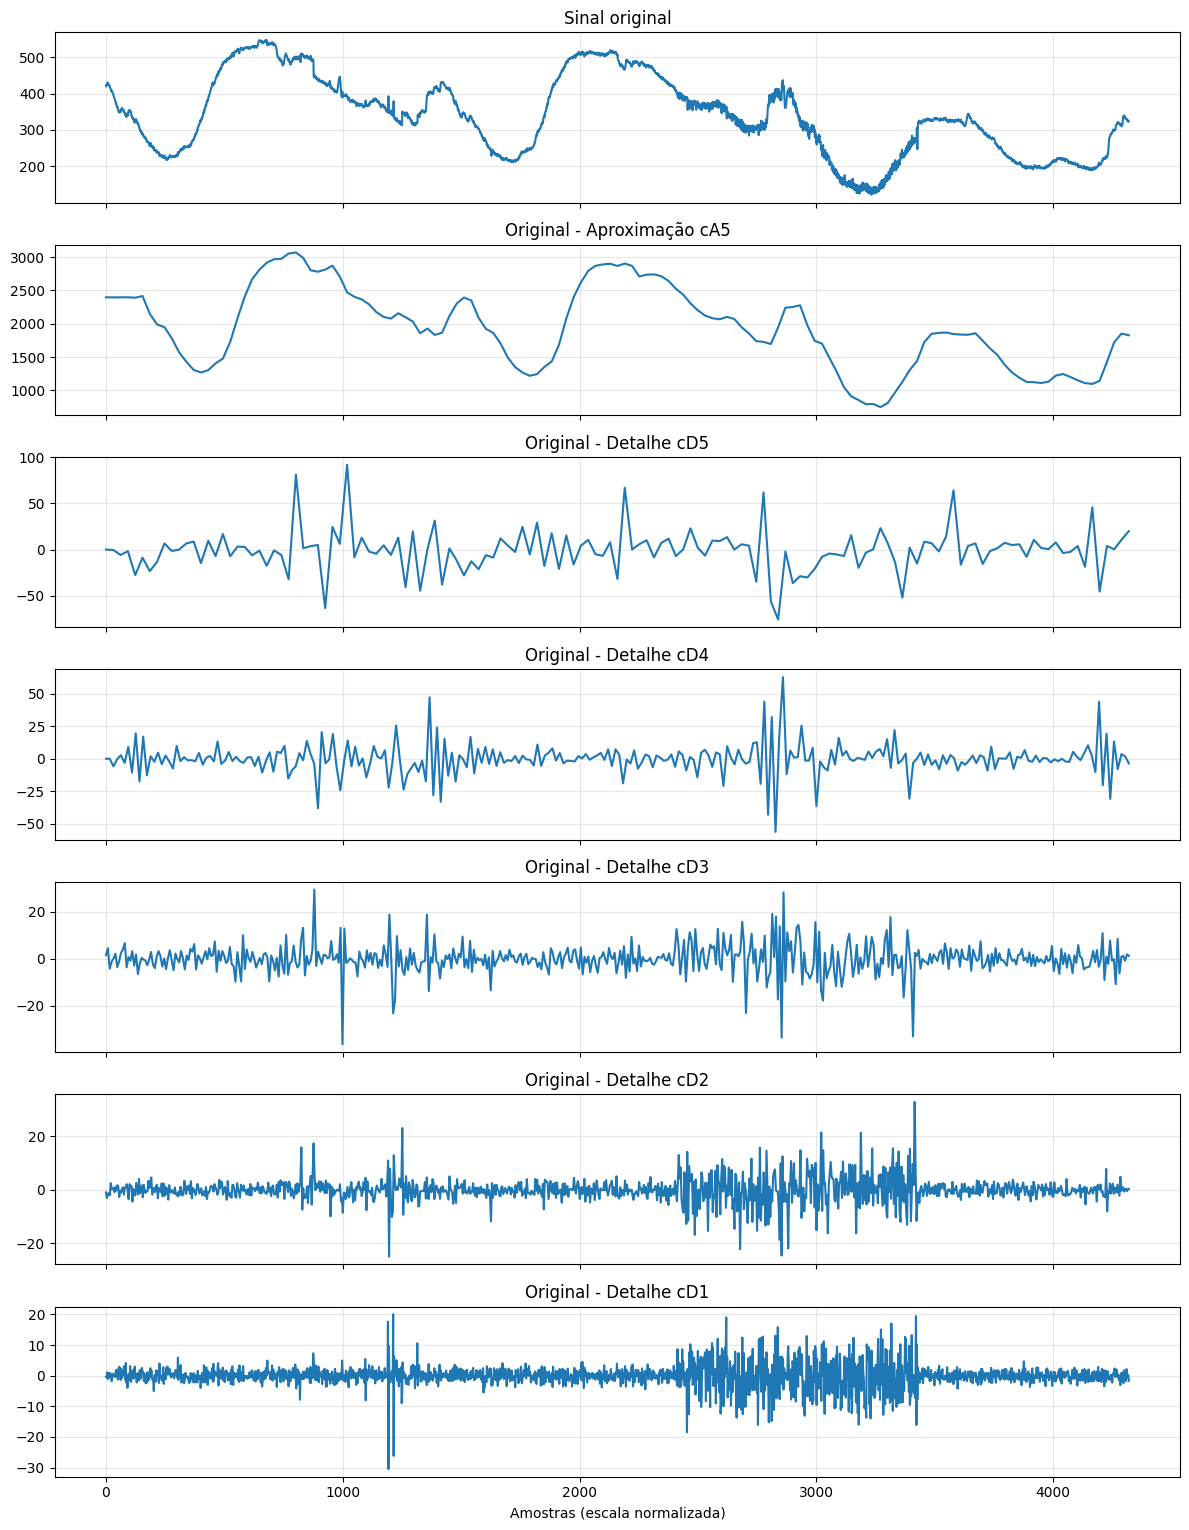

In [ ]:
import scipy.io as sio

mat_path = glob.glob('/content/gele7317-proc-sin/**/leleccum.mat', recursive=True)[0]
d = sio.loadmat(mat_path)
x = np.squeeze(d['leleccum']).astype(float)
N = len(x)
fs = 1.0

t = np.arange(N) / fs
f = np.fft.rfftfreq(N, 1 / fs)
X = np.fft.rfft(x)
fig, ax = plt.subplots(2, 1, figsize=(12, 7))
ax[0].plot(t, x); ax[0].set_title('leleccum no tempo'); ax[0].set_xlabel('n'); ax[0].grid(alpha=.3)
ax[1].plot(f, np.abs(X)); ax[1].set_title('Espectro (|DFT|)'); ax[1].set_xlabel('Frequência (ciclos/amostra)'); ax[1].grid(alpha=.3)
plt.tight_layout(); plt.show()

w = pywt.Wavelet('db4')
bancos = {'Análise passa-baixas': w.dec_lo, 'Análise passa-altas': w.dec_hi,
          'Síntese passa-baixas': w.rec_lo, 'Síntese passa-altas': w.rec_hi}
fig, ax = plt.subplots(2, 2, figsize=(11, 6))
for a, (nome, h) in zip(ax.ravel(), bancos.items()):
    a.stem(h); a.set_title(nome); a.grid(alpha=.3)
    print(nome, np.round(h, 6))
plt.tight_layout(); plt.show()

nivel = 5
coefs = pywt.wavedec(x, 'db4', level=nivel)
nomes = [f'Aproximação cA{nivel}'] + [f'Detalhe cD{j}' for j in range(nivel, 0, -1)]

def plota_coefs(coefs, titulo):
    fig, ax = plt.subplots(nivel + 2, 1, figsize=(12, 2.2 * (nivel + 2)), sharex=True)
    ax[0].plot(x); ax[0].set_title('Sinal original'); ax[0].grid(alpha=.3)
    for a, c, nome in zip(ax[1:], coefs, nomes):
        tt = np.linspace(0, N - 1, len(c))
        a.plot(tt, c); a.set_title(f'{titulo} - {nome}'); a.grid(alpha=.3)
    ax[-1].set_xlabel('Amostras (escala normalizada)')
    plt.tight_layout(); plt.show()

plota_coefs(coefs, 'Original')

sigma estimado = 1.8660 | limiar universal = 7.6352


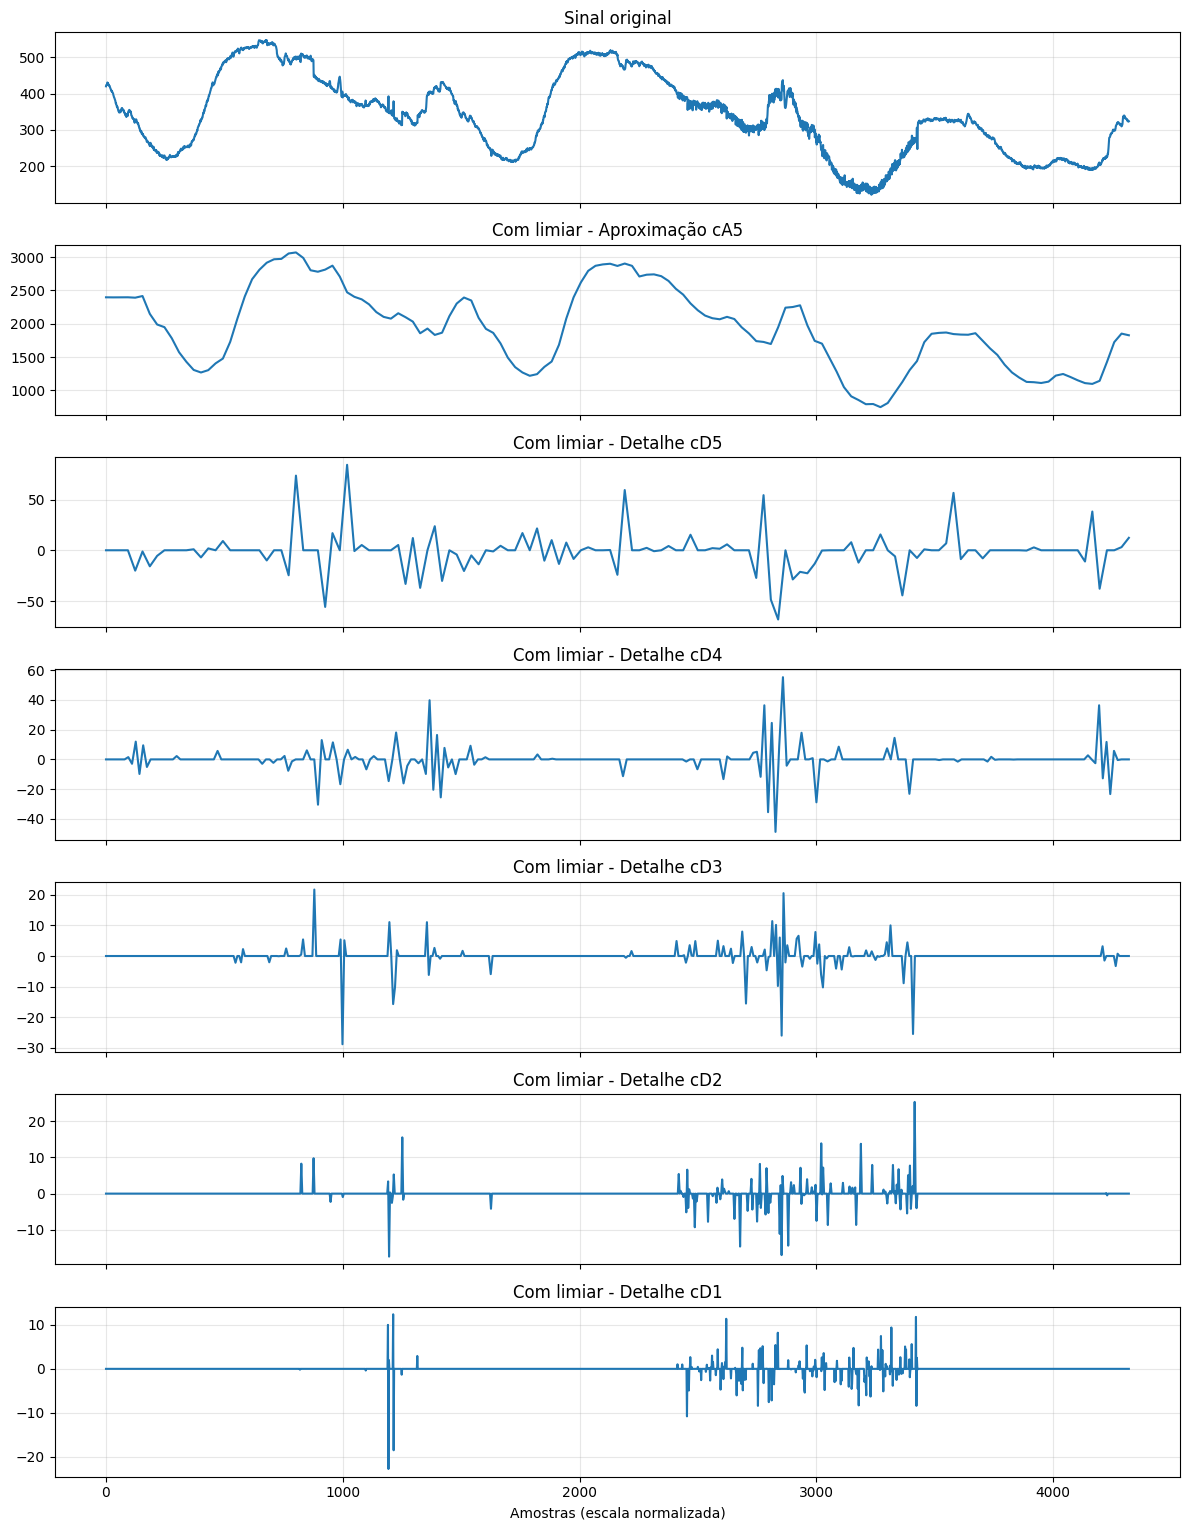

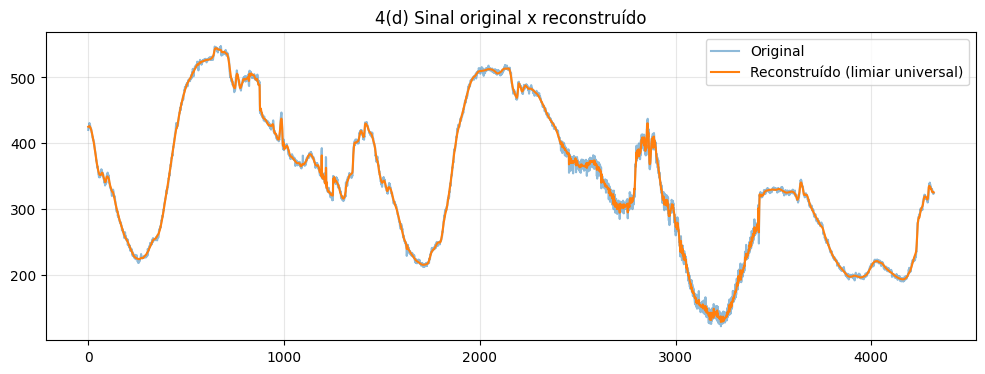

fator 0.25: lam=1.909, MSE=2.1586, zerados=52.4%
fator 0.5: lam=3.818, MSE=5.5048, zerados=73.8%
fator 1: lam=7.635, MSE=12.1321, zerados=86.1%
fator 2: lam=15.270, MSE=21.4326, zerados=93.8%


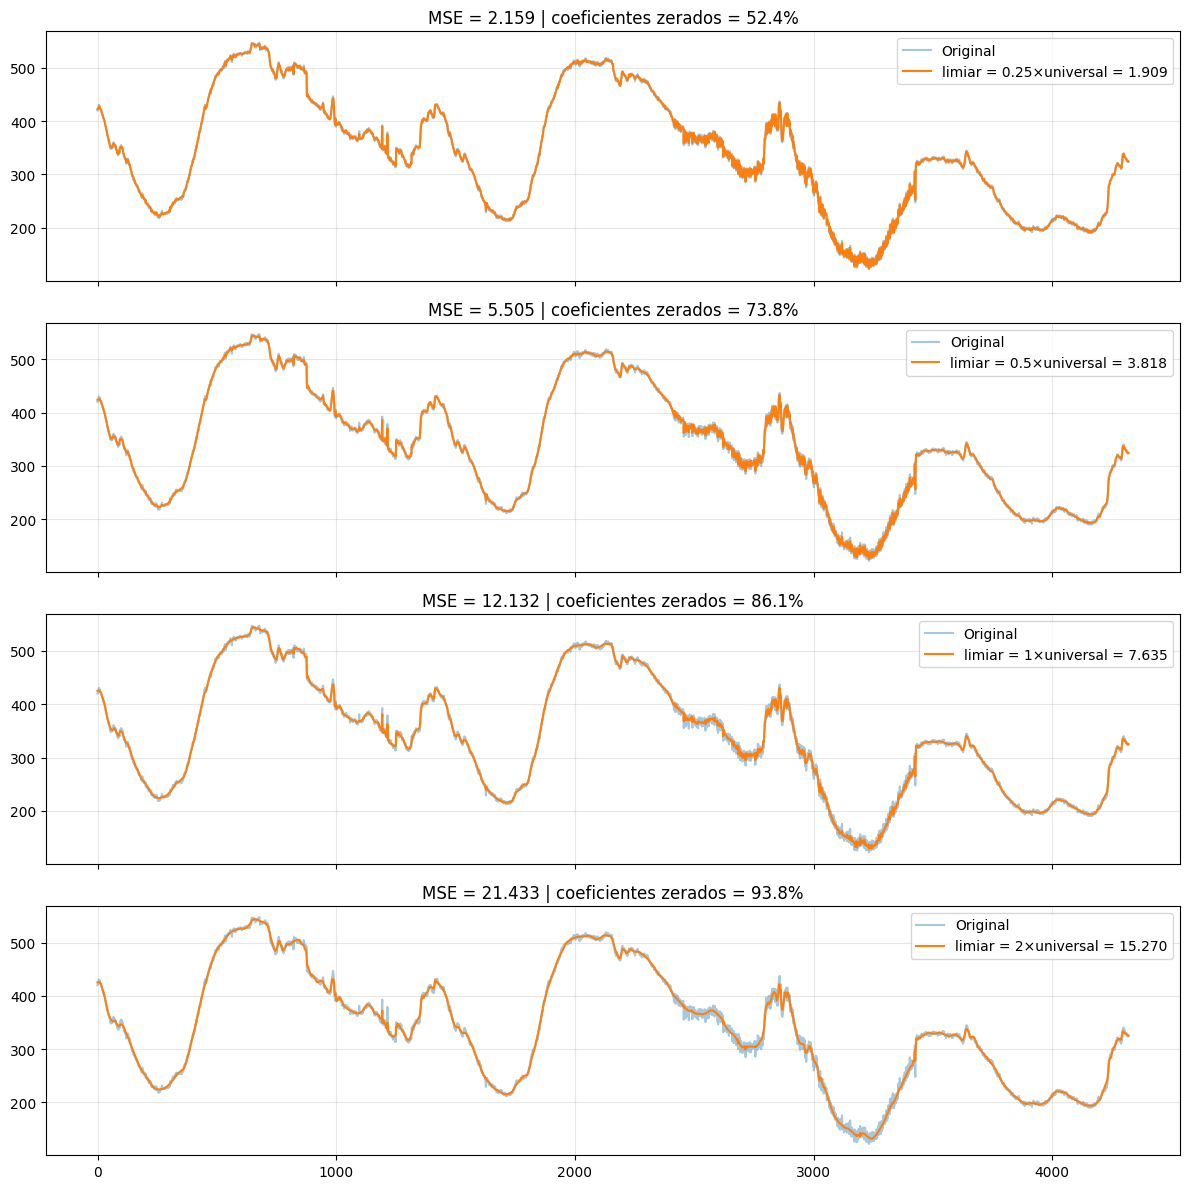

modo=hard | limiar na aproximação=False | MSE=5.8836
modo=hard | limiar na aproximação=True  | MSE=5.8836
modo=soft | limiar na aproximação=False | MSE=12.1321
modo=soft | limiar na aproximação=True  | MSE=13.9573
DFT fração 0.01: MSE=176.0930, mantidos=0.5%
DFT fração 0.03: MSE=515.0561, mantidos=0.3%
DFT fração 0.05: MSE=515.0561, mantidos=0.3%
DFT fração 0.1: MSE=2769.2525, mantidos=0.2%


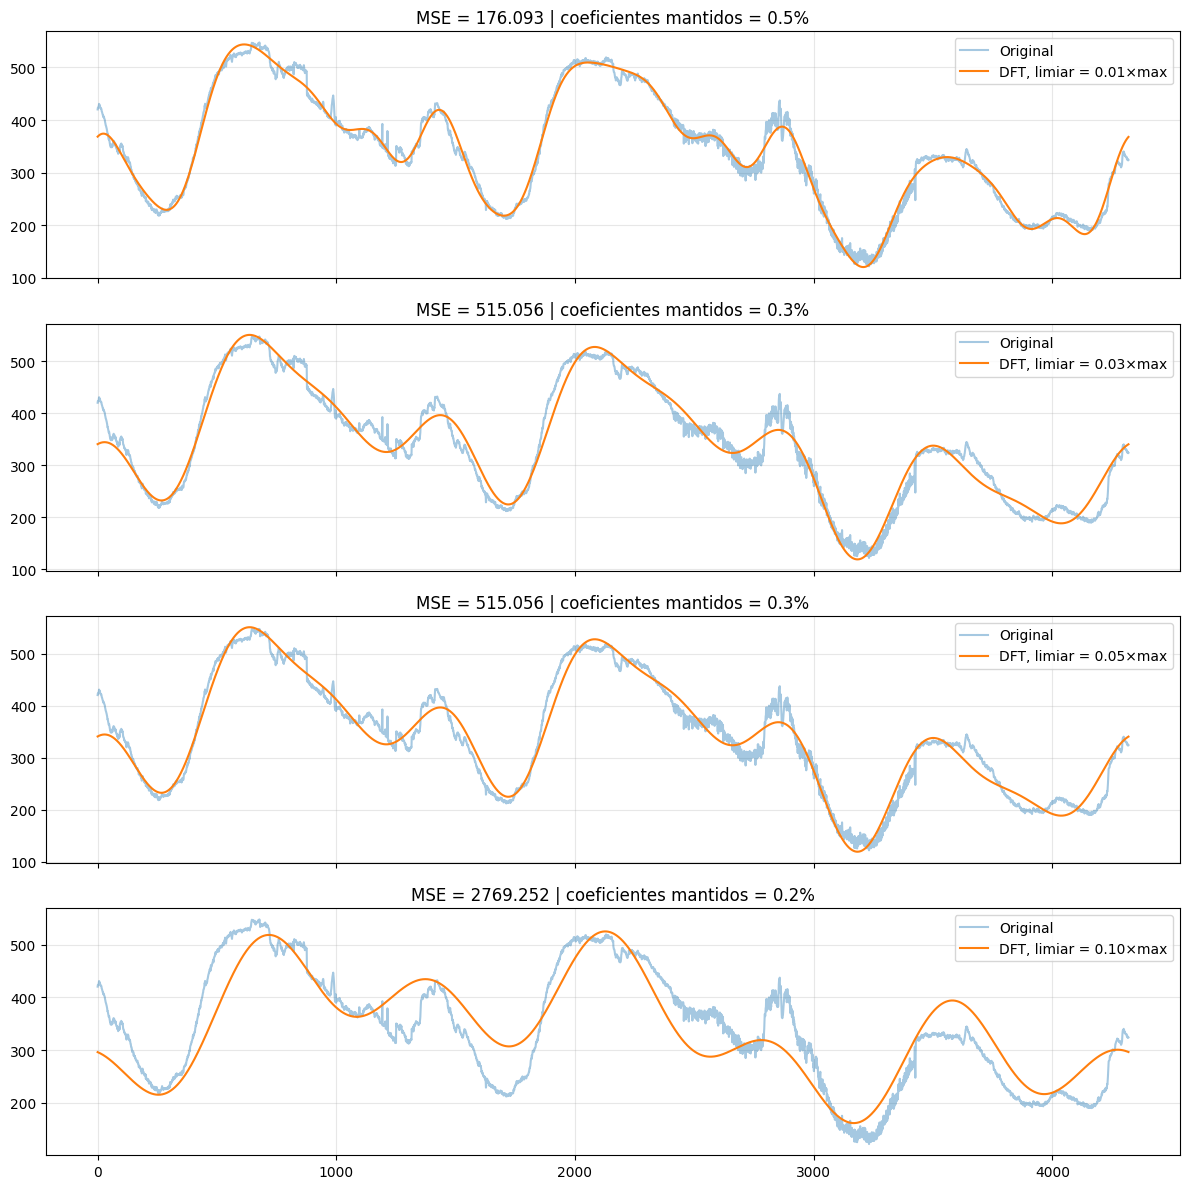

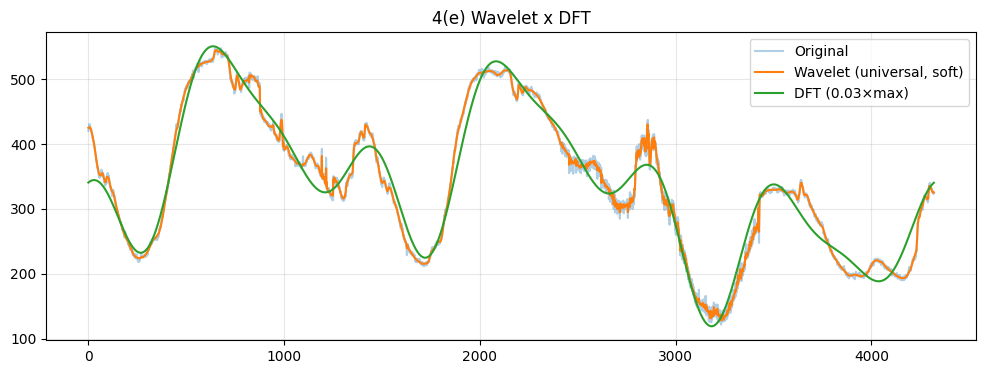

In [ ]:
sigma = np.median(np.abs(coefs[-1])) / 0.6745
lam_univ = sigma * np.sqrt(2 * np.log(N))
print(f"sigma estimado = {sigma:.4f} | limiar universal = {lam_univ:.4f}")

def denoise_wavelet(lam, modo='soft', limiar_aprox=False):
    novo = [coefs[0] if not limiar_aprox else pywt.threshold(coefs[0], lam, mode=modo)]
    novo += [pywt.threshold(c, lam, mode=modo) for c in coefs[1:]]
    return novo

coefs_den = denoise_wavelet(lam_univ, 'soft')
plota_coefs(coefs_den, 'Com limiar')
x_den = pywt.waverec(coefs_den, 'db4')[:N]
plt.figure(figsize=(12, 4))
plt.plot(x, alpha=.5, label='Original'); plt.plot(x_den, label='Reconstruído (limiar universal)')
plt.legend(); plt.grid(alpha=.3); plt.title('4(d) Sinal original x reconstruído'); plt.show()

fatores = [0.25, 0.5, 1, 2]
fig, ax = plt.subplots(len(fatores), 1, figsize=(12, 3 * len(fatores)), sharex=True)
for a, fa in zip(ax, fatores):
    lam = fa * lam_univ
    cd = denoise_wavelet(lam, 'soft')
    xr = pywt.waverec(cd, 'db4')[:N]
    zeros = sum(np.sum(c == 0) for c in cd) / sum(len(c) for c in cd) * 100
    mse = np.mean((x - xr) ** 2)
    a.plot(x, alpha=.4, label='Original'); a.plot(xr, label=f'limiar = {fa}×universal = {lam:.3f}')
    a.set_title(f'MSE = {mse:.3f} | coeficientes zerados = {zeros:.1f}%'); a.legend(); a.grid(alpha=.3)
    print(f"fator {fa}: lam={lam:.3f}, MSE={mse:.4f}, zerados={zeros:.1f}%")
plt.tight_layout(); plt.show()

for modo in ['hard', 'soft']:
    for la in [False, True]:
        xr = pywt.waverec(denoise_wavelet(lam_univ, modo, la), 'db4')[:N]
        print(f"modo={modo:4s} | limiar na aproximação={la!s:5s} | MSE={np.mean((x - xr)**2):.4f}")

Xf = np.fft.fft(x)
fracoes = [0.01, 0.03, 0.05, 0.10]
fig, ax = plt.subplots(len(fracoes), 1, figsize=(12, 3 * len(fracoes)), sharex=True)
for a, fr in zip(ax, fracoes):
    thr = fr * np.max(np.abs(Xf))
    Xt = np.where(np.abs(Xf) >= thr, Xf, 0)
    xd = np.real(np.fft.ifft(Xt))
    mant = np.mean(Xt != 0) * 100
    a.plot(x, alpha=.4, label='Original'); a.plot(xd, label=f'DFT, limiar = {fr:.2f}×max')
    a.set_title(f'MSE = {np.mean((x - xd)**2):.3f} | coeficientes mantidos = {mant:.1f}%'); a.legend(); a.grid(alpha=.3)
    print(f"DFT fração {fr}: MSE={np.mean((x - xd)**2):.4f}, mantidos={mant:.1f}%")
plt.tight_layout(); plt.show()

xw = pywt.waverec(denoise_wavelet(lam_univ, 'soft'), 'db4')[:N]
xd = np.real(np.fft.ifft(np.where(np.abs(Xf) >= 0.03 * np.max(np.abs(Xf)), Xf, 0)))
plt.figure(figsize=(12, 4))
plt.plot(x, alpha=.35, label='Original'); plt.plot(xw, label='Wavelet (universal, soft)'); plt.plot(xd, label='DFT (0.03×max)')
plt.legend(); plt.grid(alpha=.3); plt.title('4(e) Wavelet x DFT'); plt.show()